
# Polymarket Trading Data: Preprocessing and Exploratory Analysis

**CMSC320 Final Project: Checkpoint 2**

Repo: https://github.com/parthm667/cmsc320-project
Dataset: https://huggingface.co/datasets/SII-WANGZJ/Polymarket_data



## 1. Data Preprocessing

### 1(a). Import

The full dataset is 107GB across five parquet files, hosted on HuggingFace. I used
`fsspec` + `pyarrow` to read remote parquet files over HTTP range requests, pulling
individual row groups without downloading the whole file.

- **`markets.parquet`** (4,049,900 rows): pulled only the 11 columns needed, then took a
  random sample of 400,000 markets (the full text columns did not fit in memory).
- **`quant.parquet`** (1.27B trades, 44.6GB): sampled 25 row groups spread evenly across
  the file (sorted by block number, so the sample spans the full trading history),
  15,000 random rows per group, giving 361,666 trades.

Fetch code: `data/processed/fetch_sample.py`. Output: `markets_sample.parquet`,
`trades_sample.parquet`.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

markets = pd.read_parquet("data/processed/markets_sample.parquet")
trades = pd.read_parquet("data/processed/trades_sample.parquet")

print("markets:", markets.shape)
print("trades: ", trades.shape)


markets: (400000, 11)
trades:  (361666, 9)



### 1(b). Parse

- `outcome_prices` is a string like `"['0', '1']"`; parse it into floats and derive
  `resolved_yes` for closed markets.
- `created_at` / `end_date` -> `duration_days`.
- `timestamp` (Unix int) -> real datetime.


In [2]:

import ast

def parse_outcome_prices(s):
    try:
        vals = ast.literal_eval(s)
        return float(vals[0]), float(vals[1])
    except (ValueError, SyntaxError, IndexError):
        return np.nan, np.nan

markets[["p_token1", "p_token2"]] = markets["outcome_prices"].apply(
    lambda s: pd.Series(parse_outcome_prices(s))
)

# for closed markets, token1 resolving to 1 means the first outcome (YES) won
markets["resolved_yes"] = np.where(
    markets["closed"] == 1,
    markets["p_token1"] >= 0.5,
    np.nan,
)

markets["duration_days"] = (markets["end_date"] - markets["created_at"]).dt.total_seconds() / 86400
trades["datetime"] = pd.to_datetime(trades["timestamp"], unit="s", utc=True)

markets[["id", "question", "volume", "closed", "p_token1", "resolved_yes", "duration_days"]].head()


,id,question,volume,closed,p_token1,resolved_yes,duration_days
0,1310557,Will Carlos Leal win by KO or TKO?,274.097744,1,0.0000,0.0,74.066644
1,674255,Will the highest temperature in New York City ...,101143.804719,1,0.0000,0.0,1.911285
2,2142429,Will Viking FK win on 2026-05-30?,131183.892235,1,0.9995,1.0,27.760382
3,4434960,2Q Spread: Missouri State (-5.5),0.000000,1,1.0000,1.0,2.555000
4,4076431,Set 2 Winner: Loureiro vs Werner,0.000000,1,0.0000,0.0,7.468021



### 1(c). Organize

Join trades to markets on `market_id` / `id`.


In [3]:

merged = trades.merge(
    markets[["id", "question", "volume", "closed", "resolved_yes", "event_title", "duration_days"]],
    left_on="market_id", right_on="id", how="inner",
)
print("merged shape:", merged.shape)
print("all trades matched a market:", len(merged) == len(trades))
merged.head(3)


merged shape: (361666, 17)
all trades matched a market: True


,timestamp,market_id,condition_id,price,usd_amount,token_amount,side,maker,taker,datetime,id,question,volume,closed,resolved_yes,event_title,duration_days
0,1671335357,240380,0x41190eb9336ae73949c04f4900f9865092e69a57cf9c...,0.35,2.0,5.71,BUY,0x7789806c754eb0af4c3abeb026c218b4ba78f823,0xa4fa812f65302529073fdeee6d375470cfb5d9bd,2022-12-18 03:49:17+00:00,240380,[Single Market] Will Donald J. Trump win the U...,6.552460e+06,1,1.0,[Single Markets] Republican Nominee 2024,972.910521
1,1671346770,240380,0x41190eb9336ae73949c04f4900f9865092e69a57cf9c...,0.35,100.0,285.71,BUY,0x7789806c754eb0af4c3abeb026c218b4ba78f823,0x7789806c754eb0af4c3abeb026c218b4ba78f823,2022-12-18 06:59:30+00:00,240380,[Single Market] Will Donald J. Trump win the U...,6.552460e+06,1,1.0,[Single Markets] Republican Nominee 2024,972.910521
2,1671346974,240380,0x41190eb9336ae73949c04f4900f9865092e69a57cf9c...,0.34,5.1,15.00,BUY,0x7789806c754eb0af4c3abeb026c218b4ba78f823,0x7789806c754eb0af4c3abeb026c218b4ba78f823,2022-12-18 07:02:54+00:00,240380,[Single Market] Will Donald J. Trump win the U...,6.552460e+06,1,1.0,[Single Markets] Republican Nominee 2024,972.910521



## 2. Basic Data Exploration


In [4]:

print("markets_sample.parquet:", markets.shape[0], "rows,", markets.shape[1], "columns")
print("trades_sample.parquet: ", trades.shape[0], "rows,", trades.shape[1], "columns")
print()
print("Missing values per column (markets):")
print(markets.isna().sum()[markets.isna().sum() > 0])
print()
print("Share of markets with zero recorded volume:", round((markets["volume"] == 0).mean(), 3))
print("Share of markets that are closed:", round((markets["closed"] == 1).mean(), 3))
markets["volume"].describe()


markets_sample.parquet: 400000 rows, 15 columns
trades_sample.parquet:  361666 rows, 10 columns

Missing values per column (markets):
p_token1           56
p_token2           56
resolved_yes    23425
dtype: int64

Share of markets with zero recorded volume: 0.412
Share of markets that are closed: 0.941


count    4.000000e+05
mean     9.181192e+04
std      3.265851e+06
min      0.000000e+00
25%      0.000000e+00
50%      3.780922e+01
75%      2.083795e+03
max      1.531479e+09
Name: volume, dtype: float64


41.2% of markets have zero volume. `volume` has mean
\$91,812, max \$1.53B, std
\$3.27M: strongly non-normal.



## 3. Method 1: Is market volume normally distributed? (Shapiro-Wilk test)

**Hypotheses:**
- H0: market volume is drawn from a normal distribution.
- H1: market volume is not normally distributed.


In [5]:

nonzero_vol = markets.loc[markets["volume"] > 0, "volume"]
log_vol = np.log10(nonzero_vol)

# Shapiro-Wilk is only valid up to ~5000 points before p-values become unreliable,
# so I draw a random subsample for the test itself (the plot still uses the full data)
sample_vol = nonzero_vol.sample(n=5000, random_state=320)
sample_log_vol = np.log10(sample_vol)

stat_raw, p_raw = stats.shapiro(sample_vol)
stat_log, p_log = stats.shapiro(sample_log_vol)

print(f"Shapiro-Wilk on raw volume:      W = {stat_raw:.4f}, p = {p_raw:.3e}")
print(f"Shapiro-Wilk on log10(volume):   W = {stat_log:.4f}, p = {p_log:.3e}")
print(f"Skewness of raw volume:    {stats.skew(nonzero_vol):.2f}")
print(f"Skewness of log10(volume): {stats.skew(log_vol):.2f}")

top1pct_share = nonzero_vol.sort_values(ascending=False).head(int(len(nonzero_vol) * 0.01)).sum() / nonzero_vol.sum()
print(f"Share of total volume held by the top 1% of traded markets: {top1pct_share:.1%}")


Shapiro-Wilk on raw volume:      W = 0.0393, p = 6.641e-95
Shapiro-Wilk on log10(volume):   W = 0.9902, p = 3.897e-18
Skewness of raw volume:    216.70
Skewness of log10(volume): 0.17
Share of total volume held by the top 1% of traded markets: 80.8%


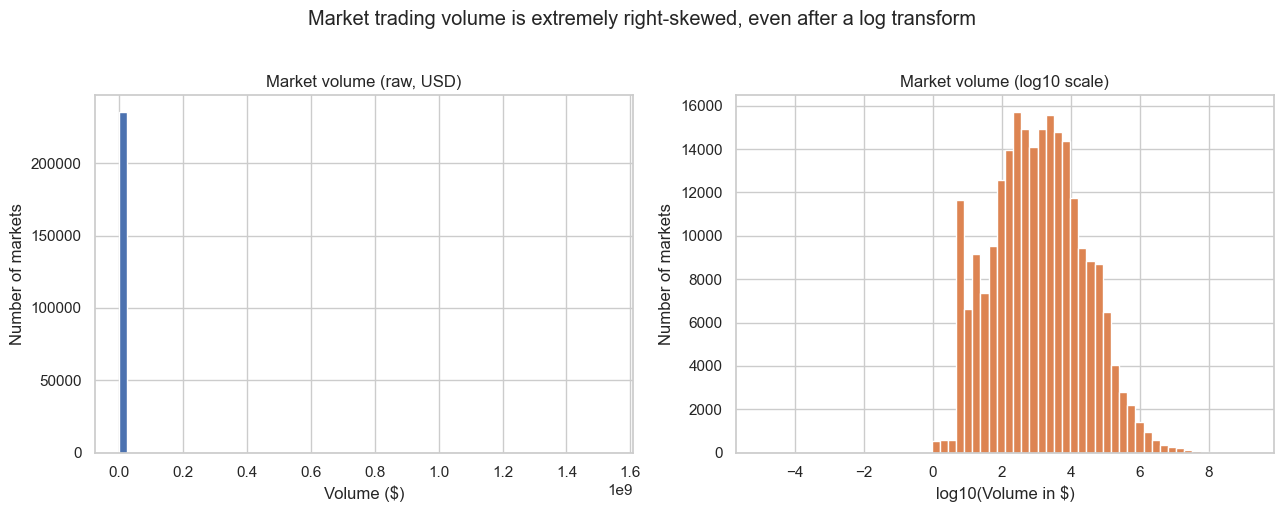

In [6]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(nonzero_vol, bins=60, color="#4C72B0")
axes[0].set_title("Market volume (raw, USD)")
axes[0].set_xlabel("Volume ($)")
axes[0].set_ylabel("Number of markets")

axes[1].hist(log_vol, bins=60, color="#DD8452")
axes[1].set_title("Market volume (log10 scale)")
axes[1].set_xlabel("log10(Volume in $)")
axes[1].set_ylabel("Number of markets")

fig.suptitle("Market trading volume is extremely right-skewed, even after a log transform", y=1.02)
plt.tight_layout()
plt.savefig("fig1_volume_distribution.png", dpi=150, bbox_inches="tight")
plt.show()



**Conclusion:** both tests reject normality (p < 0.001). Raw skewness is
216.7; the top 1% of traded markets hold ~81% of total volume.
Volume should be log-transformed for any downstream modeling.



## 4. Method 2: Do trade prices cluster near 0 and 1? (Chi-square goodness-of-fit test)

**Hypotheses:**
- H0: trade prices are uniformly distributed across \[0, 1\].
- H1: trade prices are not uniformly distributed.


In [7]:

bins = np.linspace(0, 1, 11)
observed_counts, bin_edges = np.histogram(trades["price"], bins=bins)
expected_counts = np.full(10, len(trades) / 10)

chi2_stat, chi2_p = stats.chisquare(f_obs=observed_counts, f_exp=expected_counts)
print("Observed counts per decile bin:", observed_counts)
print(f"Chi-square statistic: {chi2_stat:.1f}, p-value: {chi2_p:.3e}")

extreme_share = ((trades["price"] <= 0.1) | (trades["price"] >= 0.9)).mean()
middle_share = ((trades["price"] > 0.4) & (trades["price"] < 0.6)).mean()
print(f"Share of trades priced at or beyond the 0-0.1 / 0.9-1.0 extremes: {extreme_share:.1%}")
print(f"Share of trades priced in the 0.4-0.6 middle band:               {middle_share:.1%}")


Observed counts per decile bin: [76119 27778 29454 31223 41619 46612 30149 21589 21710 35413]
Chi-square statistic: 64511.9, p-value: 0.000e+00
Share of trades priced at or beyond the 0-0.1 / 0.9-1.0 extremes: 31.3%
Share of trades priced in the 0.4-0.6 middle band:               22.4%


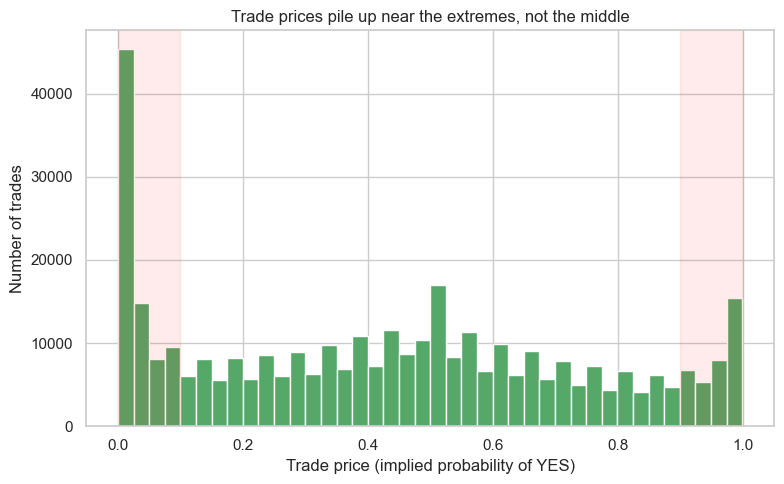

In [8]:

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(trades["price"], bins=40, color="#55A868")
ax.axvspan(0, 0.1, color="red", alpha=0.08)
ax.axvspan(0.9, 1.0, color="red", alpha=0.08)
ax.set_title("Trade prices pile up near the extremes, not the middle")
ax.set_xlabel("Trade price (implied probability of YES)")
ax.set_ylabel("Number of trades")
plt.tight_layout()
plt.savefig("fig2_price_distribution.png", dpi=150, bbox_inches="tight")
plt.show()



**Conclusion:** rejects uniformity (p < 0.001). 31.3% of trades fall in the
extreme 20% of the price range (vs. 20% expected); 21.5% alone sit at
price <= 0.10, vs. 9.8% at price >= 0.90. The middle band is close to its
uniform share (22.4%): the extremes, not the middle, are overrepresented.



## 5. Method 3: Are trades larger when prices are more extreme? (Mann-Whitney U test)

**Hypotheses:**
- H0: extreme-price trades and middle-price trades come from the same underlying
  distribution of trade size.
- H1: extreme-price trades are drawn from a different distribution of trade size than
  middle-price trades.


In [9]:

extreme_trades = trades.loc[(trades["price"] <= 0.1) | (trades["price"] >= 0.9), "usd_amount"]
middle_trades = trades.loc[(trades["price"] > 0.4) & (trades["price"] < 0.6), "usd_amount"]

u_stat, u_p = stats.mannwhitneyu(extreme_trades, middle_trades, alternative="two-sided")

print(f"n (extreme-price trades): {len(extreme_trades)}, median size: ${extreme_trades.median():.2f}")
print(f"n (middle-price trades):  {len(middle_trades)}, median size: ${middle_trades.median():.2f}")
print(f"Mann-Whitney U: {u_stat:.1f}, p-value: {u_p:.3e}")


n (extreme-price trades): 113164, median size: $1.00
n (middle-price trades):  80949, median size: $3.25
Mann-Whitney U: 3181897176.5, p-value: 0.000e+00


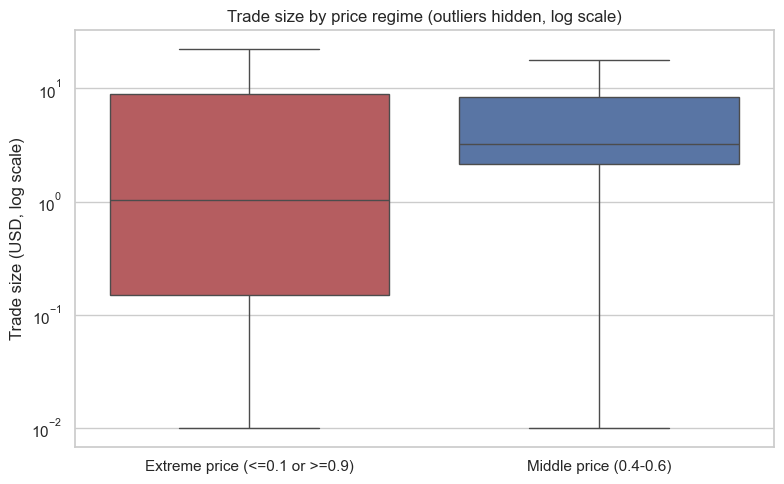

In [10]:

plot_df = pd.concat([
    pd.DataFrame({"usd_amount": extreme_trades, "group": "Extreme price (<=0.1 or >=0.9)"}),
    pd.DataFrame({"usd_amount": middle_trades, "group": "Middle price (0.4-0.6)"}),
])
plot_df = plot_df[plot_df["usd_amount"] > 0]

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=plot_df, x="group", y="usd_amount", hue="group", legend=False,
            showfliers=False, ax=ax, palette=["#C44E52", "#4C72B0"])
ax.set_yscale("log")
ax.set_title("Trade size by price regime (outliers hidden, log scale)")
ax.set_xlabel("")
ax.set_ylabel("Trade size (USD, log scale)")
plt.tight_layout()
plt.savefig("fig3_tradesize_by_price.png", dpi=150, bbox_inches="tight")
plt.show()



**Conclusion:** significant difference (p < 0.001). Extreme-price trades have a lower
median size ($1.00) than middle-price trades ($3.25).
